#TUGAS LAB 1

### Buatlah model klasterisasi dengan menggunakan Agglomerative Clustering dengan seluruh variabel yang dapat digunakan.

### Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_credit_card. Tunjukkan bentuk cluster-nya berdasarkan dua fitur tersebut.

### Tentukan nilai silhouette score dan DBI dari model.

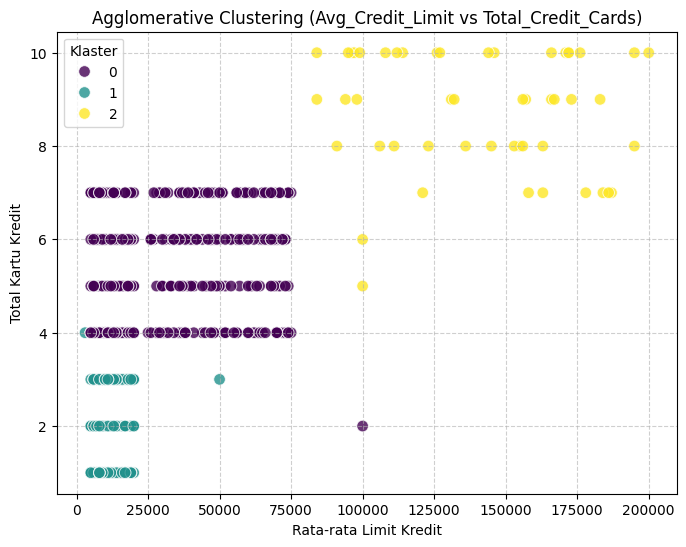

=== Hasil Evaluasi Agglomerative Clustering ===
Silhouette Score : 0.5148
Davies-Bouldin Index (DBI): 0.6810


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 1. Load Dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

# 2. Pra-pemrosesan Data
# Menghapus kolom identifier yang tidak relevan (Sl_No, Customer Key)
X_agglo = df.drop(columns=['Sl_No', 'Customer Key'], errors='ignore')
# standarisasi
scaler = StandardScaler()
X_agglo_scaled = scaler.fit_transform(X_agglo)

# 3. Membangun model Agglomerative Clustering
agglo = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df['Agglo_Cluster'] = agglo.fit_predict(X_agglo_scaled)

# 4. Visualisasi (Avg_Credit_Limit vs Total_Credit_Cards)
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df,
                x='Avg_Credit_Limit',
                y='Total_Credit_Cards',
                hue='Agglo_Cluster',
                palette='viridis',
                s=70, alpha=0.8)
plt.title('Agglomerative Clustering (Avg_Credit_Limit vs Total_Credit_Cards)')
plt.xlabel('Rata-rata Limit Kredit')
plt.ylabel('Total Kartu Kredit')
plt.legend(title='Klaster')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 5. Evaluasi Metrik Model (Silhouette & DBI)
sil_score_agglo = silhouette_score(X_agglo_scaled, df['Agglo_Cluster'])
dbi_score_agglo = davies_bouldin_score(X_agglo_scaled, df['Agglo_Cluster'])

print("=== Hasil Evaluasi Agglomerative Clustering ===")
print(f"Silhouette Score : {sil_score_agglo:.4f}")
print(f"Davies-Bouldin Index (DBI): {dbi_score_agglo:.4f}")